# Hotel Review Sentiment Model Comparison

This notebook compares three sentiment approaches against the same prepared splits:

1. **Baseline:** TF-IDF bigrams + Logistic Regression
2. **Contextual embeddings:** `sentence-transformers/all-MiniLM-L6-v2` + calibrated Logistic Regression
3. **Domain adaptation:** SetFit using the same Sentence Transformer body

It also evaluates:

- accuracy, balanced accuracy, macro/weighted F1 and per-class metrics;
- confusion matrices;
- log loss, Brier score and expected calibration error;
- single-review and batch latency;
- model behavior on a mixed/contrastive challenge set;
- prediction disagreements and high-confidence errors.

> Run from the repository in which `Backend/`, `Data/`, `Frontend/`, and `Logs/` exist. The notebook automatically discovers the project root.


## Prerequisites

Activate the backend environment, then install the experiment dependencies once:

```bash
cd Backend
pip install sentence-transformers setfit datasets seaborn
```

The first Sentence Transformer or SetFit execution downloads the configured model. Set `LOCAL_FILES_ONLY = True` only after the model is cached locally.


In [1]:
from __future__ import annotations

import json
import os
import platform
import random
import sys
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Any

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: 3.10.12
Platform: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.35
scikit-learn: 1.7.2
PyTorch: 2.14.1+cu130
CUDA available: False


In [2]:
from pathlib import Path

# If your notebook is 1 folder deep from the root (e.g., project/notebooks/main.ipynb)
project_root = Path.cwd().parent 

# If your notebook is 2 folders deep (e.g., project/research/notebooks/main.ipynb)
PROJECT_ROOT = Path.cwd().parents[1]

print(PROJECT_ROOT)

BACKEND_DIR = PROJECT_ROOT / "backend"
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
EXPERIMENT_DIR = BACKEND_DIR / "models/sentiment_experiments"
CACHE_DIR = EXPERIMENT_DIR / "embedding_cache"
REPORT_DIR = EXPERIMENT_DIR / "reports"
CHALLENGE_PATH = DATA_DIR / "labeled/sentiment_challenge_set.csv"


PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)


print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("EXPERIMENT_DIR:", EXPERIMENT_DIR)


/home/vasant/projects/multi-ml-modelling
PROJECT_ROOT: /home/vasant/projects/multi-ml-modelling
PROCESSED_DIR: /home/vasant/projects/multi-ml-modelling/data/processed
EXPERIMENT_DIR: /home/vasant/projects/multi-ml-modelling/backend/models/sentiment_experiments


In [3]:
# Experiment configuration. Start conservatively on CPU, then widen the experiment.
TEXT_COLUMN = "review"
LABEL_COLUMN = "sentiment"
LABELS = ["negative", "neutral", "positive"]
LABEL_TO_ID = {label: i for i, label in enumerate(LABELS)}
ID_TO_LABEL = {i: label for label, i in LABEL_TO_ID.items()}

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
LOCAL_FILES_ONLY = False
EMBEDDING_BATCH_SIZE = 64 if torch.cuda.is_available() else 32

# None uses every row. Set an integer for a fast trial while validating code.
MAX_TRAIN_ROWS = None
MAX_VALID_ROWS = None
MAX_TEST_ROWS = None

# SetFit is more expensive. Default is a controlled stratified sample per class.
RUN_SETFIT = True
SETFIT_TRAIN_PER_CLASS = 500
SETFIT_VALID_PER_CLASS = 150
SETFIT_EPOCHS = 2
SETFIT_BATCH_SIZE = 16

print({
    "embedding_model": EMBEDDING_MODEL_NAME,
    "embedding_batch_size": EMBEDDING_BATCH_SIZE,
    "run_setfit": RUN_SETFIT,
})


{'embedding_model': 'sentence-transformers/all-MiniLM-L6-v2', 'embedding_batch_size': 32, 'run_setfit': True}


In [4]:
import psutil

print(
    round(
        psutil.virtual_memory().total
        / (1024**3),
        2
    ),
    "GB"
)

15.4 GB


In [5]:
def load_split(name: str, max_rows: int | None = None) -> pd.DataFrame:
    path = PROCESSED_DIR / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Missing split: {path}")
    df = pd.read_csv(path)
    required = {TEXT_COLUMN, LABEL_COLUMN}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path.name} is missing columns: {sorted(missing)}")
    df = df.dropna(subset=[TEXT_COLUMN, LABEL_COLUMN]).copy()
    df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str).str.strip()
    df = df[df[TEXT_COLUMN].ne("")]
    unknown = set(df[LABEL_COLUMN].unique()) - set(LABELS)
    if unknown:
        raise ValueError(f"Unknown sentiment labels in {path.name}: {sorted(unknown)}")
    if max_rows and len(df) > max_rows:
        parts = []
        per_class = max(1, max_rows // len(LABELS))
        for label in LABELS:
            group = df[df[LABEL_COLUMN] == label]
            parts.append(group.sample(min(per_class, len(group)), random_state=SEED))
        df = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
    return df.reset_index(drop=True)

train_df = load_split("train", MAX_TRAIN_ROWS)
valid_df = load_split("validation", MAX_VALID_ROWS)
test_df = load_split("test", MAX_TEST_ROWS)

for name, df in [("train", train_df), ("validation", valid_df), ("test", test_df)]:
    print(f"\n{name}: {len(df):,}")
    print(df[LABEL_COLUMN].value_counts().reindex(LABELS, fill_value=0))



train: 14,343
sentiment
negative     2250
neutral      1528
positive    10565
Name: count, dtype: int64

validation: 2,049
sentiment
negative     321
neutral      219
positive    1509
Name: count, dtype: int64

test: 4,099
sentiment
negative     643
neutral      437
positive    3019
Name: count, dtype: int64


In [6]:
# Data audit: text length and exact leakage checks.
def normalized_key(series: pd.Series) -> pd.Series:
    return (
        series.astype(str)
        .str.lower()
        .str.replace(r"[^\w\s]", "", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

for df in [train_df, valid_df, test_df]:
    df["word_count_experiment"] = df[TEXT_COLUMN].str.split().str.len()

length_stats = pd.DataFrame({
    "train": train_df["word_count_experiment"].describe(percentiles=[.5,.9,.95,.99]),
    "validation": valid_df["word_count_experiment"].describe(percentiles=[.5,.9,.95,.99]),
    "test": test_df["word_count_experiment"].describe(percentiles=[.5,.9,.95,.99]),
})
display(length_stats)

train_keys = set(normalized_key(train_df[TEXT_COLUMN]))
valid_keys = set(normalized_key(valid_df[TEXT_COLUMN]))
test_keys = set(normalized_key(test_df[TEXT_COLUMN]))
print("Exact normalized overlap train/validation:", len(train_keys & valid_keys))
print("Exact normalized overlap train/test:", len(train_keys & test_keys))
print("Exact normalized overlap validation/test:", len(valid_keys & test_keys))


,train,validation,test
count,14343.000000,2049.000000,4099.00000
mean,103.138953,108.291850,106.74628
std,98.702251,117.044061,98.48194
min,8.000000,9.000000,7.00000
50%,76.000000,78.000000,79.00000
90%,198.000000,208.000000,210.20000
95%,272.000000,282.600000,279.10000
99%,487.000000,551.120000,527.10000
max,1639.000000,1931.000000,1383.00000


Exact normalized overlap train/validation: 0
Exact normalized overlap train/test: 0
Exact normalized overlap validation/test: 0


## Shared evaluation utilities

The calibration metric below bins maximum predicted confidence and compares mean confidence with empirical accuracy. Brier score is reported as the multiclass mean squared probability error.


In [7]:
def expected_calibration_error(y_true, probabilities, classes, bins=10) -> float:
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    pred_idx = probabilities.argmax(axis=1)
    predictions = np.asarray(classes)[pred_idx]
    confidences = probabilities.max(axis=1)
    correctness = (predictions == y_true).astype(float)
    edges = np.linspace(0.0, 1.0, bins + 1)
    ece = 0.0
    for lower, upper in zip(edges[:-1], edges[1:]):
        mask = (confidences > lower) & (confidences <= upper)
        if mask.any():
            ece += mask.mean() * abs(correctness[mask].mean() - confidences[mask].mean())
    return float(ece)


def multiclass_brier(y_true, probabilities, classes) -> float:
    class_to_index = {label: i for i, label in enumerate(classes)}
    one_hot = np.zeros_like(probabilities, dtype=float)
    for row, label in enumerate(y_true):
        one_hot[row, class_to_index[label]] = 1.0
    return float(np.mean(np.sum((probabilities - one_hot) ** 2, axis=1)))


def evaluate_predictions(name, y_true, predictions, probabilities, classes, latency=None):
    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "macro_f1": f1_score(y_true, predictions, average="macro"),
        "weighted_f1": f1_score(y_true, predictions, average="weighted"),
        "log_loss": log_loss(y_true, probabilities, labels=list(classes)),
        "brier_score": multiclass_brier(y_true, probabilities, list(classes)),
        "ece_10_bins": expected_calibration_error(y_true, probabilities, list(classes)),
        "high_confidence_errors": int(((np.max(probabilities, axis=1) >= .80) & (np.asarray(predictions) != np.asarray(y_true))).sum()),
    }
    if latency:
        metrics.update(latency)
    report = classification_report(y_true, predictions, labels=LABELS, output_dict=True, zero_division=0)
    return metrics, report


def plot_confusion(y_true, predictions, title):
    matrix = confusion_matrix(y_true, predictions, labels=LABELS)
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


def latency_test(predict_fn, texts, warmup=5, repeats=40):
    sample = list(texts[: max(warmup, min(repeats, len(texts)))])
    for text in sample[:warmup]:
        predict_fn([text])
    timings = []
    for text in sample[:repeats]:
        start = time.perf_counter()
        predict_fn([text])
        timings.append((time.perf_counter() - start) * 1000)
    batch = sample[: min(32, len(sample))]
    start = time.perf_counter()
    predict_fn(batch)
    batch_ms = (time.perf_counter() - start) * 1000
    return {
        "single_p50_ms": float(np.percentile(timings, 50)),
        "single_p95_ms": float(np.percentile(timings, 95)),
        "batch_size": len(batch),
        "batch_total_ms": batch_ms,
        "batch_per_item_ms": batch_ms / max(len(batch), 1),
    }

all_metrics = []
all_reports = {}
all_predictions = {}


## Model A: TF-IDF + Logistic Regression baseline


,precision,recall,f1-score,support
negative,0.754237,0.830482,0.790526,643.000000
neutral,0.387674,0.446224,0.414894,437.000000
positive,0.945637,0.904604,0.924666,3019.000000
accuracy,0.844108,0.844108,0.844108,0.844108
macro avg,0.695849,0.727104,0.710028,4099.000000
weighted avg,0.856127,0.844108,0.849276,4099.000000


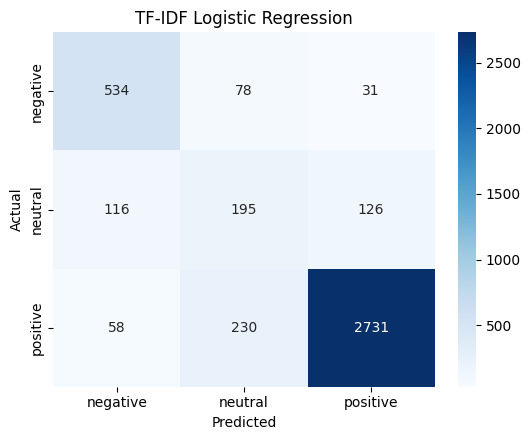

In [8]:
tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words=None,
        min_df=2,
        max_df=0.95,
        max_features=50_000,
        ngram_range=(1, 2),
        sublinear_tf=True,
    )),
    ("classifier", LogisticRegression(
        max_iter=2_500,
        class_weight="balanced",
        random_state=SEED,
    )),
])

start = time.perf_counter()
tfidf_model.fit(train_df[TEXT_COLUMN], train_df[LABEL_COLUMN])
tfidf_train_seconds = time.perf_counter() - start

tfidf_pred = tfidf_model.predict(test_df[TEXT_COLUMN])
tfidf_prob = tfidf_model.predict_proba(test_df[TEXT_COLUMN])
tfidf_classes = list(tfidf_model.classes_)
tfidf_latency = latency_test(tfidf_model.predict_proba, test_df[TEXT_COLUMN].tolist())
tfidf_metrics, tfidf_report = evaluate_predictions(
    "tfidf_logistic", test_df[LABEL_COLUMN], tfidf_pred, tfidf_prob, tfidf_classes, tfidf_latency
)
tfidf_metrics["train_seconds"] = tfidf_train_seconds
all_metrics.append(tfidf_metrics)
all_reports["tfidf_logistic"] = tfidf_report
all_predictions["tfidf_logistic"] = (tfidf_pred, tfidf_prob, tfidf_classes)

display(pd.DataFrame(tfidf_report).T)
plot_confusion(test_df[LABEL_COLUMN], tfidf_pred, "TF-IDF Logistic Regression")


## Model B: Frozen Sentence Transformer embeddings + calibrated Logistic Regression


In [9]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer(
    EMBEDDING_MODEL_NAME,
    local_files_only=LOCAL_FILES_ONLY,
)
print("Encoder maximum sequence length:", encoder.max_seq_length)
print("Embedding dimension:", encoder.get_sentence_embedding_dimension())


def embedding_cache_path(split_name: str, frame: pd.DataFrame) -> Path:
    safe_model = EMBEDDING_MODEL_NAME.replace("/", "__")
    return CACHE_DIR / f"{safe_model}_{split_name}_{len(frame)}.npy"


def encode_split(split_name: str, frame: pd.DataFrame) -> np.ndarray:
    path = embedding_cache_path(split_name, frame)
    if path.exists():
        print("Loading embedding cache:", path.name)
        return np.load(path)
    print("Encoding", split_name, len(frame), "reviews")
    matrix = encoder.encode(
        frame[TEXT_COLUMN].tolist(),
        batch_size=EMBEDDING_BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    np.save(path, matrix)
    return matrix

X_train_emb = encode_split("train", train_df)
X_valid_emb = encode_split("validation", valid_df)
X_test_emb = encode_split("test", test_df)
print(X_train_emb.shape, X_valid_emb.shape, X_test_emb.shape)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Encoder maximum sequence length: 256
Embedding dimension: 384
Loading embedding cache: sentence-transformers__all-MiniLM-L6-v2_train_14343.npy
Loading embedding cache: sentence-transformers__all-MiniLM-L6-v2_validation_2049.npy
Loading embedding cache: sentence-transformers__all-MiniLM-L6-v2_test_4099.npy
(14343, 384) (2049, 384) (4099, 384)


,precision,recall,f1-score,support
negative,0.712271,0.785381,0.747041,643.000000
neutral,0.432692,0.102975,0.166359,437.000000
positive,0.881619,0.959589,0.918953,3019.000000
accuracy,0.840937,0.840937,0.840937,0.840937
macro avg,0.675527,0.615982,0.610784,4099.000000
weighted avg,0.807193,0.840937,0.811751,4099.000000


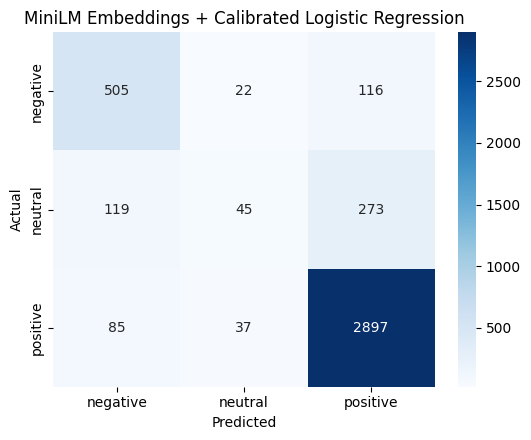

In [10]:
# Fit the classifier on train, then calibrate probabilities on validation only.
base_embedding_classifier = LogisticRegression(
    max_iter=2_500,
    class_weight="balanced",
    random_state=SEED,
)

start = time.perf_counter()
base_embedding_classifier.fit(X_train_emb, train_df[LABEL_COLUMN])
calibrated_embedding_classifier = CalibratedClassifierCV(
    estimator=base_embedding_classifier,
    method="sigmoid",
    cv="prefit",
)
calibrated_embedding_classifier.fit(X_valid_emb, valid_df[LABEL_COLUMN])
embedding_train_seconds = time.perf_counter() - start

embedding_pred = calibrated_embedding_classifier.predict(X_test_emb)
embedding_prob = calibrated_embedding_classifier.predict_proba(X_test_emb)
embedding_classes = list(calibrated_embedding_classifier.classes_)


def embedding_predict_proba(texts):
    matrix = encoder.encode(
        list(texts),
        batch_size=EMBEDDING_BATCH_SIZE,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False,
    )
    return calibrated_embedding_classifier.predict_proba(matrix)

embedding_latency = latency_test(embedding_predict_proba, test_df[TEXT_COLUMN].tolist())
embedding_metrics, embedding_report = evaluate_predictions(
    "minilm_calibrated_logistic",
    test_df[LABEL_COLUMN],
    embedding_pred,
    embedding_prob,
    embedding_classes,
    embedding_latency,
)
embedding_metrics["train_seconds_excluding_embedding_generation"] = embedding_train_seconds
all_metrics.append(embedding_metrics)
all_reports["minilm_calibrated_logistic"] = embedding_report
all_predictions["minilm_calibrated_logistic"] = (embedding_pred, embedding_prob, embedding_classes)

display(pd.DataFrame(embedding_report).T)
plot_confusion(test_df[LABEL_COLUMN], embedding_pred, "MiniLM Embeddings + Calibrated Logistic Regression")


## Model C: SetFit domain adaptation

SetFit is optional because it modifies the encoder and is more expensive than frozen-embedding classification. The default experiment uses a stratified subset per label so that CPU validation remains practical. Set `RUN_SETFIT = False` to skip it, or increase `SETFIT_TRAIN_PER_CLASS` after the pipeline is verified.


In [ ]:
def stratified_per_class(df: pd.DataFrame, count: int) -> pd.DataFrame:
    parts = []
    for label in LABELS:
        group = df[df[LABEL_COLUMN] == label]
        parts.append(group.sample(min(count, len(group)), random_state=SEED))
    return pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)

setfit_model = None
if RUN_SETFIT:
    from datasets import Dataset
    from setfit import SetFitModel, Trainer, TrainingArguments

    setfit_train_df = stratified_per_class(train_df, SETFIT_TRAIN_PER_CLASS).copy()
    setfit_valid_df = stratified_per_class(valid_df, SETFIT_VALID_PER_CLASS).copy()
    setfit_train_df["label"] = setfit_train_df[LABEL_COLUMN].map(LABEL_TO_ID)
    setfit_valid_df["label"] = setfit_valid_df[LABEL_COLUMN].map(LABEL_TO_ID)

    setfit_train_ds = Dataset.from_pandas(
        setfit_train_df[[TEXT_COLUMN, "label"]].rename(columns={TEXT_COLUMN: "text"}),
        preserve_index=False,
    )
    setfit_valid_ds = Dataset.from_pandas(
        setfit_valid_df[[TEXT_COLUMN, "label"]].rename(columns={TEXT_COLUMN: "text"}),
        preserve_index=False,
    )

    setfit_model = SetFitModel.from_pretrained(
        EMBEDDING_MODEL_NAME,
        labels=LABELS,
        local_files_only=LOCAL_FILES_ONLY,
    )
    args = TrainingArguments(
        output_dir=str(EXPERIMENT_DIR / "setfit_checkpoints"),
        batch_size=SETFIT_BATCH_SIZE,
        num_epochs=SETFIT_EPOCHS,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        seed=SEED,
    )
    trainer = Trainer(
        model=setfit_model,
        args=args,
        train_dataset=setfit_train_ds,
        eval_dataset=setfit_valid_ds,
        metric="accuracy",
        column_mapping={"text": "text", "label": "label"},
    )

    start = time.perf_counter()
    trainer.train()
    setfit_train_seconds = time.perf_counter() - start

    raw_pred = np.asarray(setfit_model.predict(test_df[TEXT_COLUMN].tolist()))
    setfit_pred = np.array([ID_TO_LABEL.get(int(x), str(x)) if not isinstance(x, str) else x for x in raw_pred])
    setfit_prob = np.asarray(setfit_model.predict_proba(test_df[TEXT_COLUMN].tolist()))
    setfit_classes = LABELS

    def setfit_predict_proba(texts):
        return np.asarray(setfit_model.predict_proba(list(texts)))

    setfit_latency = latency_test(setfit_predict_proba, test_df[TEXT_COLUMN].tolist(), repeats=20)
    setfit_metrics, setfit_report = evaluate_predictions(
        "setfit_minilm",
        test_df[LABEL_COLUMN],
        setfit_pred,
        setfit_prob,
        setfit_classes,
        setfit_latency,
    )
    setfit_metrics["train_seconds"] = setfit_train_seconds
    setfit_metrics["train_rows"] = len(setfit_train_df)
    all_metrics.append(setfit_metrics)
    all_reports["setfit_minilm"] = setfit_report
    all_predictions["setfit_minilm"] = (setfit_pred, setfit_prob, setfit_classes)
    display(pd.DataFrame(setfit_report).T)
    plot_confusion(test_df[LABEL_COLUMN], setfit_pred, "SetFit MiniLM")
else:
    print("SetFit skipped by configuration.")


## Aggregate model comparison


In [11]:
comparison_df = pd.DataFrame(all_metrics).set_index("model")
metric_order = [
    "accuracy", "balanced_accuracy", "macro_f1", "weighted_f1",
    "log_loss", "brier_score", "ece_10_bins", "high_confidence_errors",
    "single_p50_ms", "single_p95_ms", "batch_per_item_ms",
]
existing = [column for column in metric_order if column in comparison_df.columns]
display(comparison_df[existing].sort_values("macro_f1", ascending=False).round(4))

neutral_rows = []
for model_name, report in all_reports.items():
    neutral_rows.append({
        "model": model_name,
        "neutral_precision": report["neutral"]["precision"],
        "neutral_recall": report["neutral"]["recall"],
        "neutral_f1": report["neutral"]["f1-score"],
    })
display(pd.DataFrame(neutral_rows).set_index("model").round(4))


,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss,brier_score,ece_10_bins,high_confidence_errors,single_p50_ms,single_p95_ms,batch_per_item_ms
model,,,,,,,,,,,
tfidf_logistic,0.8441,0.7271,0.7100,0.8493,0.4556,0.2462,0.1089,28,0.7544,1.0660,0.1278
minilm_calibrated_logistic,0.8409,0.6160,0.6108,0.8118,0.4279,0.2298,0.0317,176,29.6786,756.0557,23.2674


,neutral_precision,neutral_recall,neutral_f1
model,,,
tfidf_logistic,0.3877,0.4462,0.4149
minilm_calibrated_logistic,0.4327,0.1030,0.1664


In [12]:
comparison_df.to_dict()

{'accuracy': {'tfidf_logistic': 0.8441083191022201,
  'minilm_calibrated_logistic': 0.8409368138570383},
 'balanced_accuracy': {'tfidf_logistic': 0.7271035149819497,
  'minilm_calibrated_logistic': 0.6159817075944606},
 'macro_f1': {'tfidf_logistic': 0.710028268194479,
  'minilm_calibrated_logistic': 0.6107844090163818},
 'weighted_f1': {'tfidf_logistic': 0.8492759284783962,
  'minilm_calibrated_logistic': 0.8117506917465377},
 'log_loss': {'tfidf_logistic': 0.4555943849946041,
  'minilm_calibrated_logistic': 0.4279441322354859},
 'brier_score': {'tfidf_logistic': 0.2462228618188328,
  'minilm_calibrated_logistic': 0.2297851681226085},
 'ece_10_bins': {'tfidf_logistic': 0.108881342057092,
  'minilm_calibrated_logistic': 0.03170783359565606},
 'high_confidence_errors': {'tfidf_logistic': 28,
  'minilm_calibrated_logistic': 176},
 'single_p50_ms': {'tfidf_logistic': 0.7543890005763387,
  'minilm_calibrated_logistic': 29.678565500944387},
 'single_p95_ms': {'tfidf_logistic': 1.06599175196

## Error analysis and model disagreements


In [13]:
error_frame = test_df[[TEXT_COLUMN, LABEL_COLUMN]].copy()
for model_name, (pred, prob, classes) in all_predictions.items():
    error_frame[f"{model_name}_prediction"] = pred
    error_frame[f"{model_name}_confidence"] = np.max(prob, axis=1)

prediction_columns = [c for c in error_frame if c.endswith("_prediction")]
error_frame["models_disagree"] = error_frame[prediction_columns].nunique(axis=1) > 1

display(
    error_frame[error_frame["models_disagree"]]
    .sort_values([LABEL_COLUMN])
    .head(40)
)

for model_name in all_predictions:
    wrong = error_frame[
        (error_frame[f"{model_name}_prediction"] != error_frame[LABEL_COLUMN])
        & (error_frame[f"{model_name}_confidence"] >= .80)
    ]
    print(f"\n{model_name}: {len(wrong)} high-confidence test errors")
    display(wrong[[TEXT_COLUMN, LABEL_COLUMN, f"{model_name}_prediction", f"{model_name}_confidence"]].head(15))


,review,sentiment,tfidf_logistic_prediction,tfidf_logistic_confidence,minilm_calibrated_logistic_prediction,minilm_calibrated_logistic_confidence,models_disagree
856,"avoid hotel travelling kids, singapore kids be...",negative,negative,0.395763,positive,0.864269,True
703,average just returned 3 day 2 night stay busin...,negative,neutral,0.614895,negative,0.465209,True
3139,okay issues husband just got 10 day stay majes...,negative,neutral,0.448847,positive,0.469777,True
715,rated travelled uk orlando wedding nyork 4 nig...,negative,neutral,0.360486,negative,0.373453,True
1323,wont reurning sorry report agree resort real h...,negative,positive,0.378455,negative,0.799049,True
2162,disappointing total 4 families looking hotel c...,negative,neutral,0.437750,negative,0.702324,True
1318,"kidding, arrived riu palace macao punta cana w...",negative,negative,0.858033,positive,0.484893,True
2188,ok welcome arrived driving rv yosemite oakland...,negative,neutral,0.500801,negative,0.798187,True
3148,nothing exciting stayed night moving phoenicia...,negative,neutral,0.530373,negative,0.491042,True
3004,"not luxury hotel not luxury hotel, regard maun...",negative,negative,0.593980,positive,0.484579,True



tfidf_logistic: 28 high-confidence test errors


,review,sentiment,tfidf_logistic_prediction,tfidf_logistic_confidence
140,poor service small dimly lit rooms definitely ...,neutral,negative,0.934290
256,"ok hotel good not good, people shower praise l...",positive,neutral,0.877541
265,"barcelona best city trip barcelona, nice busy ...",neutral,positive,0.875748
670,"pleasant stay, not sure hotel getting high rat...",neutral,positive,0.891404
776,mixed views stayed 3 nights singapore stopover...,neutral,negative,0.873135
983,disappointing major service issues surprised g...,neutral,negative,0.889432
1019,beautiful atmosphere customer service construc...,neutral,negative,0.906371
1063,excellent location good hotel short break righ...,neutral,positive,0.840884
1210,"not impressed, better, n't worst experience no...",neutral,negative,0.924023
1322,fine hotel fine location bargain price looking...,positive,neutral,0.823931



minilm_calibrated_logistic: 176 high-confidence test errors


,review,sentiment,minilm_calibrated_logistic_prediction,minilm_calibrated_logistic_confidence
0,"great location nice staff mattresses soft, jus...",neutral,positive,0.834351
1,"nice hotel nice hotel good area explore, arriv...",neutral,positive,0.852856
18,beautiful beach iberostar bavaro feb 25 mar 4 ...,neutral,positive,0.808190
102,"pleased, worried negative review saw online, g...",neutral,positive,0.842796
110,cold sterile uncourteous tripa hotel voted 77t...,neutral,positive,0.810788
126,great place relax husband planned trip puerto ...,neutral,positive,0.862210
156,non smoking not completely true expensive hote...,neutral,negative,0.806288
175,great husband visited majestic colonial august...,neutral,positive,0.983340
223,accomodations fit mofongo just returned 4 day ...,neutral,positive,0.937211
228,glass half ok hate mail unreasonable 3 stars r...,neutral,negative,0.900543


In [15]:
error_frame[error_frame["models_disagree"]].to_csv(REPORT_DIR / "disagreement_analysis.csv", index=False)

## Mixed-review challenge set

The source dataset has no independently annotated `mixed` class. The challenge set therefore evaluates expected **polarity tendency** plus a separate `is_mixed` flag. Review and correct these labels manually before treating challenge scores as acceptance evidence.


In [ ]:
challenge_seed = [
    {
        "case_id": "business_wifi",
        "review": "The location is unbeatable for corporate meetings, and the staff was professional. However, the room Wi-Fi kept dropping every ten minutes, making client calls a nightmare.",
        "expected_sentiment": "negative",
        "is_mixed": True,
        "notes": "Positive location/service; high-impact connectivity failure.",
    },
    {
        "case_id": "vacation_noise",
        "review": "The ocean-view suite was breathtaking and clean. Unfortunately, paper-thin walls and loud neighbors kept us awake, and pool-bar service was slow.",
        "expected_sentiment": "negative",
        "is_mixed": True,
        "notes": "Strong scenery praise; sleep and service failure.",
    },
    {
        "case_id": "budget_cleanliness",
        "review": "The central location and low price were useful, but dust under the bed and a clogged shower drain were disappointing and nothing was fixed.",
        "expected_sentiment": "negative",
        "is_mixed": True,
        "notes": "Value praise; cleanliness and recovery failure.",
    },
    {
        "case_id": "foodie_bed",
        "review": "The restaurant and wine pairing were excellent, but the mattress felt like a wooden plank and the air conditioner rattled all night.",
        "expected_sentiment": "negative",
        "is_mixed": True,
        "notes": "Dining praise; room and sleep failure.",
    },
    {
        "case_id": "family_checkin",
        "review": "The children loved the water park and game room, but check-in was chaotic and connecting rooms were not ready. Management offered free parking.",
        "expected_sentiment": "neutral",
        "is_mixed": True,
        "notes": "Positive amenities, failed check-in, partial recovery.",
    },
    {
        "case_id": "clear_positive",
        "review": "The room was spotless, the bed was comfortable, and every staff member was helpful. I would happily return.",
        "expected_sentiment": "positive",
        "is_mixed": False,
        "notes": "Clear positive control.",
    },
    {
        "case_id": "clear_negative",
        "review": "The room was dirty, the shower was broken, and staff ignored every request. I would not stay again.",
        "expected_sentiment": "negative",
        "is_mixed": False,
        "notes": "Clear negative control.",
    },
    {
        "case_id": "neutral_factual",
        "review": "The hotel is three blocks from the station. The room includes a desk, television, and shower.",
        "expected_sentiment": "neutral",
        "is_mixed": False,
        "notes": "Factual neutral control.",
    },
]

if not CHALLENGE_PATH.exists():
    pd.DataFrame(challenge_seed).to_csv(CHALLENGE_PATH, index=False)
    print("Created challenge template:", CHALLENGE_PATH)
else:
    print("Using existing challenge set:", CHALLENGE_PATH)

challenge_df = pd.read_csv(CHALLENGE_PATH)
display(challenge_df)


In [ ]:
def predict_with_embedding_model(texts):
    matrix = encoder.encode(
        list(texts), batch_size=EMBEDDING_BATCH_SIZE,
        convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False,
    )
    return calibrated_embedding_classifier.predict(matrix), calibrated_embedding_classifier.predict_proba(matrix), embedding_classes

challenge_outputs = challenge_df.copy()
model_predictors = {
    "tfidf_logistic": lambda texts: (tfidf_model.predict(texts), tfidf_model.predict_proba(texts), tfidf_classes),
    "minilm_calibrated_logistic": predict_with_embedding_model,
}
if RUN_SETFIT and setfit_model is not None:
    def predict_with_setfit(texts):
        raw = np.asarray(setfit_model.predict(list(texts)))
        pred = np.array([ID_TO_LABEL.get(int(x), str(x)) if not isinstance(x, str) else x for x in raw])
        return pred, np.asarray(setfit_model.predict_proba(list(texts))), LABELS
    model_predictors["setfit_minilm"] = predict_with_setfit

challenge_scores = []
for model_name, predict_fn in model_predictors.items():
    pred, prob, classes = predict_fn(challenge_df[TEXT_COLUMN].tolist())
    challenge_outputs[f"{model_name}_prediction"] = pred
    challenge_outputs[f"{model_name}_confidence"] = np.max(prob, axis=1)
    challenge_scores.append({
        "model": model_name,
        "challenge_accuracy": accuracy_score(challenge_df["expected_sentiment"], pred),
        "mixed_case_accuracy": accuracy_score(
            challenge_df.loc[challenge_df["is_mixed"], "expected_sentiment"],
            np.asarray(pred)[challenge_df["is_mixed"].to_numpy()],
        ),
    })

display(challenge_outputs)
display(pd.DataFrame(challenge_scores).set_index("model").round(4))


## Acceptance decision and artifact export


In [ ]:
# Suggested gate: contextual model must beat baseline macro F1, preserve neutral recall,
# and not increase high-confidence errors. Adjust only after reviewing business costs.
summary = comparison_df.reset_index().copy()
baseline = summary[summary["model"] == "tfidf_logistic"].iloc[0]
summary["beats_baseline_macro_f1"] = summary["macro_f1"] > baseline["macro_f1"]
summary["no_more_high_confidence_errors"] = summary["high_confidence_errors"] <= baseline["high_confidence_errors"]
neutral_metric_df = pd.DataFrame(neutral_rows)
baseline_neutral_recall = neutral_metric_df.loc[
    neutral_metric_df["model"] == "tfidf_logistic", "neutral_recall"
].iloc[0]
summary = summary.merge(neutral_metric_df[["model", "neutral_recall"]], on="model", how="left")
summary["preserves_neutral_recall"] = summary["neutral_recall"] >= baseline_neutral_recall
summary["passes_initial_gate"] = (
    summary["beats_baseline_macro_f1"]
    & summary["no_more_high_confidence_errors"]
    & summary["preserves_neutral_recall"]
)
display(summary[[
    "model", "macro_f1", "neutral_recall", "high_confidence_errors",
    "single_p95_ms", "passes_initial_gate"
]].round(4))

comparison_path = REPORT_DIR / "sentiment_model_comparison.csv"
challenge_output_path = REPORT_DIR / "challenge_predictions.csv"
report_path = REPORT_DIR / "sentiment_experiment_report.json"
comparison_df.reset_index().to_csv(comparison_path, index=False)
challenge_outputs.to_csv(challenge_output_path, index=False)
report_payload = {
    "configuration": {
        "embedding_model": EMBEDDING_MODEL_NAME,
        "labels": LABELS,
        "seed": SEED,
        "setfit_enabled": RUN_SETFIT,
        "setfit_train_per_class": SETFIT_TRAIN_PER_CLASS if RUN_SETFIT else None,
    },
    "comparison": json.loads(comparison_df.reset_index().to_json(orient="records")),
    "classification_reports": all_reports,
    "initial_gate": json.loads(summary.to_json(orient="records")),
}
report_path.write_text(json.dumps(report_payload, indent=2), encoding="utf-8")
print("Saved:")
print(" -", comparison_path)
print(" -", challenge_output_path)
print(" -", report_path)


In [ ]:
# Save candidate artifacts only after reviewing the comparison table.
tfidf_path = EXPERIMENT_DIR / "tfidf_baseline.joblib"
embedding_classifier_path = EXPERIMENT_DIR / "minilm_calibrated_classifier.joblib"
joblib.dump(tfidf_model, tfidf_path)
joblib.dump(calibrated_embedding_classifier, embedding_classifier_path)

if RUN_SETFIT and setfit_model is not None:
    setfit_path = EXPERIMENT_DIR / "setfit_minilm"
    setfit_model.save_pretrained(str(setfit_path))
    print("SetFit model:", setfit_path)

print("TF-IDF baseline:", tfidf_path)
print("Embedding classifier:", embedding_classifier_path)
print("Encoder is referenced by name and cached through Hugging Face:", EMBEDDING_MODEL_NAME)


## What to share for joint validation

After running the notebook, share either the executed notebook or these generated files:

- `Backend/models/sentiment_experiments/reports/sentiment_model_comparison.csv`
- `Backend/models/sentiment_experiments/reports/challenge_predictions.csv`
- `Backend/models/sentiment_experiments/reports/sentiment_experiment_report.json`

Also share:

- CPU model and available RAM;
- whether CUDA was available;
- any changed challenge-set labels and why;
- the confusion matrices, especially neutral predictions;
- any reviews where the advanced model remains confidently wrong.

Do **not** replace the production sentiment artifact until the acceptance gate and manual challenge-set review are both satisfactory.
